## Q3
กำหนดคลาส Account ให้ จงเขียนคลาส Bank ในส่วนที่กำหนดให้สมบูรณ์ โดยมีฟังก์ชันต่อไปนี้
- `__init__(self, profiles)` ฟังก์ชันสำหรับการสร้างบัญชี (accounts) ในธนาคาร ตามข้อมูลที่มีใน dictionary ชื่อ profiles โดย accounts เป็น dictionary ที่มี key เป็น ชื่อบัญชี ซึ่งเป็น key ของ profiles หนึ่ง ๆ และมี value เป็น instance ของคลาส Account ที่มียอดเงินเริ่มต้น (initial_balance) เท่ากับ value ของ profiles ที่ตรงกับชื่อบัญชีนั้น ๆ เช่น
    - ถ้า profiles มีค่าเป็น {'Carol':1000,'Marta':-100} ดังนั้น accounts ที่เป็น dictionary ของคลาส Bank จะมีค่าเป็น {'Carol':Account object ที่มี initial_balance เป็น 1000,'Marta':Account object ที่มี initial_balance เป็น -100}
- `transfer(self,from_who,to_who,amt)` ฟังก์ชันสำหรับการโอนเงินจากบัญชีชื่อ from_who ไปที่บัญชีชื่อ to_who ด้วยจำนวน amt
- `get_names_in_debt(self)` ฟังก์ชันนี้คืนค่าเป็นลิสต์ของรายชื่อที่ติดหนี้กับธนาคาร นั่นคือยอดเงินในบัญชีติดลบ
- `update_with_interest(self,interest_rate)` ฟังก์ชันสำหรับการอัพเดททุกบัญชีในธนาคารด้วยการคิดดอกเบี้ยเงินฝากและดอกเบี้ยเงินกู้

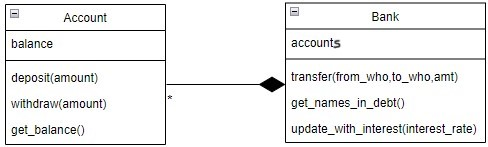

In [42]:
class Account:
    def __init__(self, initial_balance=0):
        self.__balance = initial_balance

    def deposit(self, amount):
        self.__balance += amount

    def withdraw(self, amount):
        self.__balance -= amount

    def get_balance(self):
        return self.__balance


class Bank:
    def __init__(self, profiles):
        self.accounts = {}
        for person in list(profiles.keys()):
            self.accounts[person] = Account(profiles[person])

    def transfer(self, from_who, to_who, amt):
        self.accounts[from_who].withdraw(amt)
        self.accounts[to_who].deposit(amt)

    def get_names_in_debt(self):
        in_debt = []
        for person in list(self.accounts.keys()):
            if (self.accounts[person].get_balance() < 0):
                in_debt.append(person)
        return in_debt

    def update_with_interest(self, interest_rate):
        for person in list(self.accounts.keys()):
            balance = self.accounts[person].get_balance()
            self.accounts[person].deposit(balance * (interest_rate / 100))

In [43]:
'''ตรวจสอบผลลัพธ์'''

csBank = Bank({'Carol': 1000, 'Marta': -100})
assert csBank.accounts['Carol'].get_balance() == 1000
assert csBank.accounts['Marta'].get_balance() == -100
print('ok')

ok


In [44]:
'''ตรวจสอบผลลัพธ์'''

csBank = Bank({'Carol': 1000, 'Marta': -100})
csBank.transfer('Carol', 'Marta', 500)
assert csBank.accounts['Carol'].get_balance() == 500
assert csBank.accounts['Marta'].get_balance() == 400
print('ok')

ok


In [45]:
'''ตรวจสอบผลลัพธ์'''

csBank = Bank({'Carol': 1000, 'Marta': -100})
assert csBank.get_names_in_debt() == ['Marta']
print('ok')

ok


In [47]:
'''ตรวจสอบผลลัพธ์'''

csBank = Bank({'Carol': 1000, 'Marta': -500})
csBank.update_with_interest(1.5)
assert csBank.accounts['Carol'].get_balance() == 1015
assert csBank.accounts['Marta'].get_balance() == -507.5, csBank.accounts['Marta'].get_balance()
print('ok')

ok
